In [ ]:
# ENGE707 Kaggle Competition
# Task 1 work

import hashlib, os, re, random
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

# Creating a seed to increase the repeatability of my results. Chose 42 because that's what I used for my previous group project work
SEED = 42
random.seed(SEED); np.random.seed(SEED)

# Look for train_labels.csv
CANDIDATES = [Path("ENEL707-Kaggle-Comp/Datasets"), Path("Datasets"), Path("data"), Path(".")]

# Locates data. Makes work easier to access and shows me that it is accessing the right folder
def locate_data():
    for c in CANDIDATES:
        for pattern in ("train_labels.csv", "*/train_labels.csv"):
            hits = sorted(c.glob(pattern))
            if hits:
                return hits[0].parent
    raise FileNotFoundError(f"train_labels.csv not found. Notebook folder: {Path.cwd()}")

DATA_DIR = locate_data()
print("Using:", DATA_DIR.resolve())

Using: C:\Users\devme\Documents\ENGE707\data_ai_foundations\Kaggle comp\ENEL707-Kaggle-Comp\Datasets


In [2]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def id_key(text):
    """Leading number of an id or filename: '00001', '1' and '00001 (copy)' all give 1."""
    m = re.match(r"\s*(\d+)", str(text))
    if m is None:
        raise ValueError(f"Expected an id starting with digits, got {text!r}")
    return int(m.group(1))

def index_folder(folder):
    """Dictionary {numeric id: file path} for every image under `folder`."""
    if not folder.is_dir():
        raise FileNotFoundError(f"Folder not found: {folder}")
    index = {}
    for p in folder.rglob("*"):                     # rglob also searches nested folders (train/train)
        if p.suffix.lower() in IMG_EXT:
            k = id_key(p.stem)
            if k in index:
                raise ValueError(f"Two files share id {k}: {index[k].name} and {p.name}")
            index[k] = p
    return index

TRAIN_INDEX = index_folder(DATA_DIR / "train")
TEST_INDEX  = index_folder(DATA_DIR / "test")
print("train images on disk:", len(TRAIN_INDEX), "| test images on disk:", len(TEST_INDEX))

train images on disk: 63660 | test images on disk: 29443


train rows: 63660 | test rows: 29443
ids with no image file -> train: 0 | test: 0
          count  percent
class                   
CatEye    13884     21.8
CatFace    6942     10.9
CatMouth   6942     10.9
CatNose    6942     10.9
DogEye    11580     18.2
DogFace    5790      9.1
DogMouth   5790      9.1
DogNose    5790      9.1
imbalance ratio (largest/smallest class): 2.40


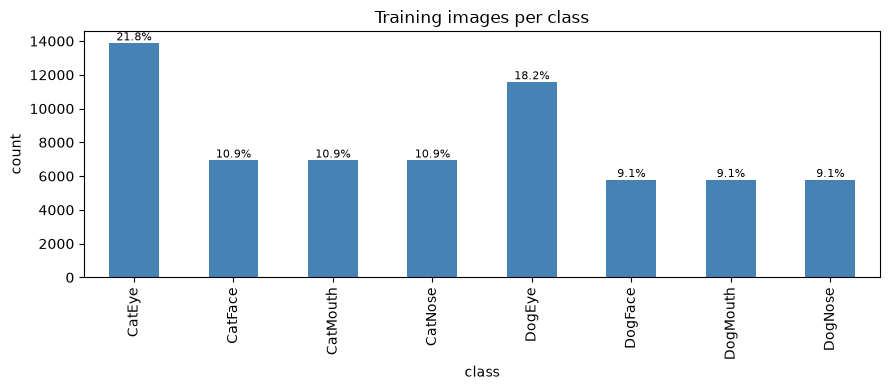

In [3]:
df  = pd.read_csv(DATA_DIR / "train_labels.csv", dtype={"image_id": str})
sub = pd.read_csv(DATA_DIR / "sample_submission.csv", dtype={"image_id": str})
assert df["image_id"].is_unique and sub["image_id"].is_unique

df["path"] = [TRAIN_INDEX.get(id_key(i)) for i in df["image_id"]]
TEST_PATHS = [TEST_INDEX.get(id_key(i)) for i in sub["image_id"]]
print("train rows:", len(df), "| test rows:", len(sub))
print("ids with no image file -> train:", int(df["path"].isna().sum()),
      "| test:", sum(p is None for p in TEST_PATHS))

counts = df["class"].value_counts().sort_index()
pct = (counts / counts.sum() * 100).round(1)
print(pd.DataFrame({"count": counts, "percent": pct}).to_string())
print(f"imbalance ratio (largest/smallest class): {counts.max() / counts.min():.2f}")

ax = counts.plot(kind="bar", figsize=(9, 4), color="steelblue")
for i, (c, p) in enumerate(zip(counts, pct)):
    ax.text(i, c, f"{p}%", ha="center", va="bottom", fontsize=8)
ax.set_title("Training images per class"); ax.set_ylabel("count")
plt.tight_layout(); plt.show()

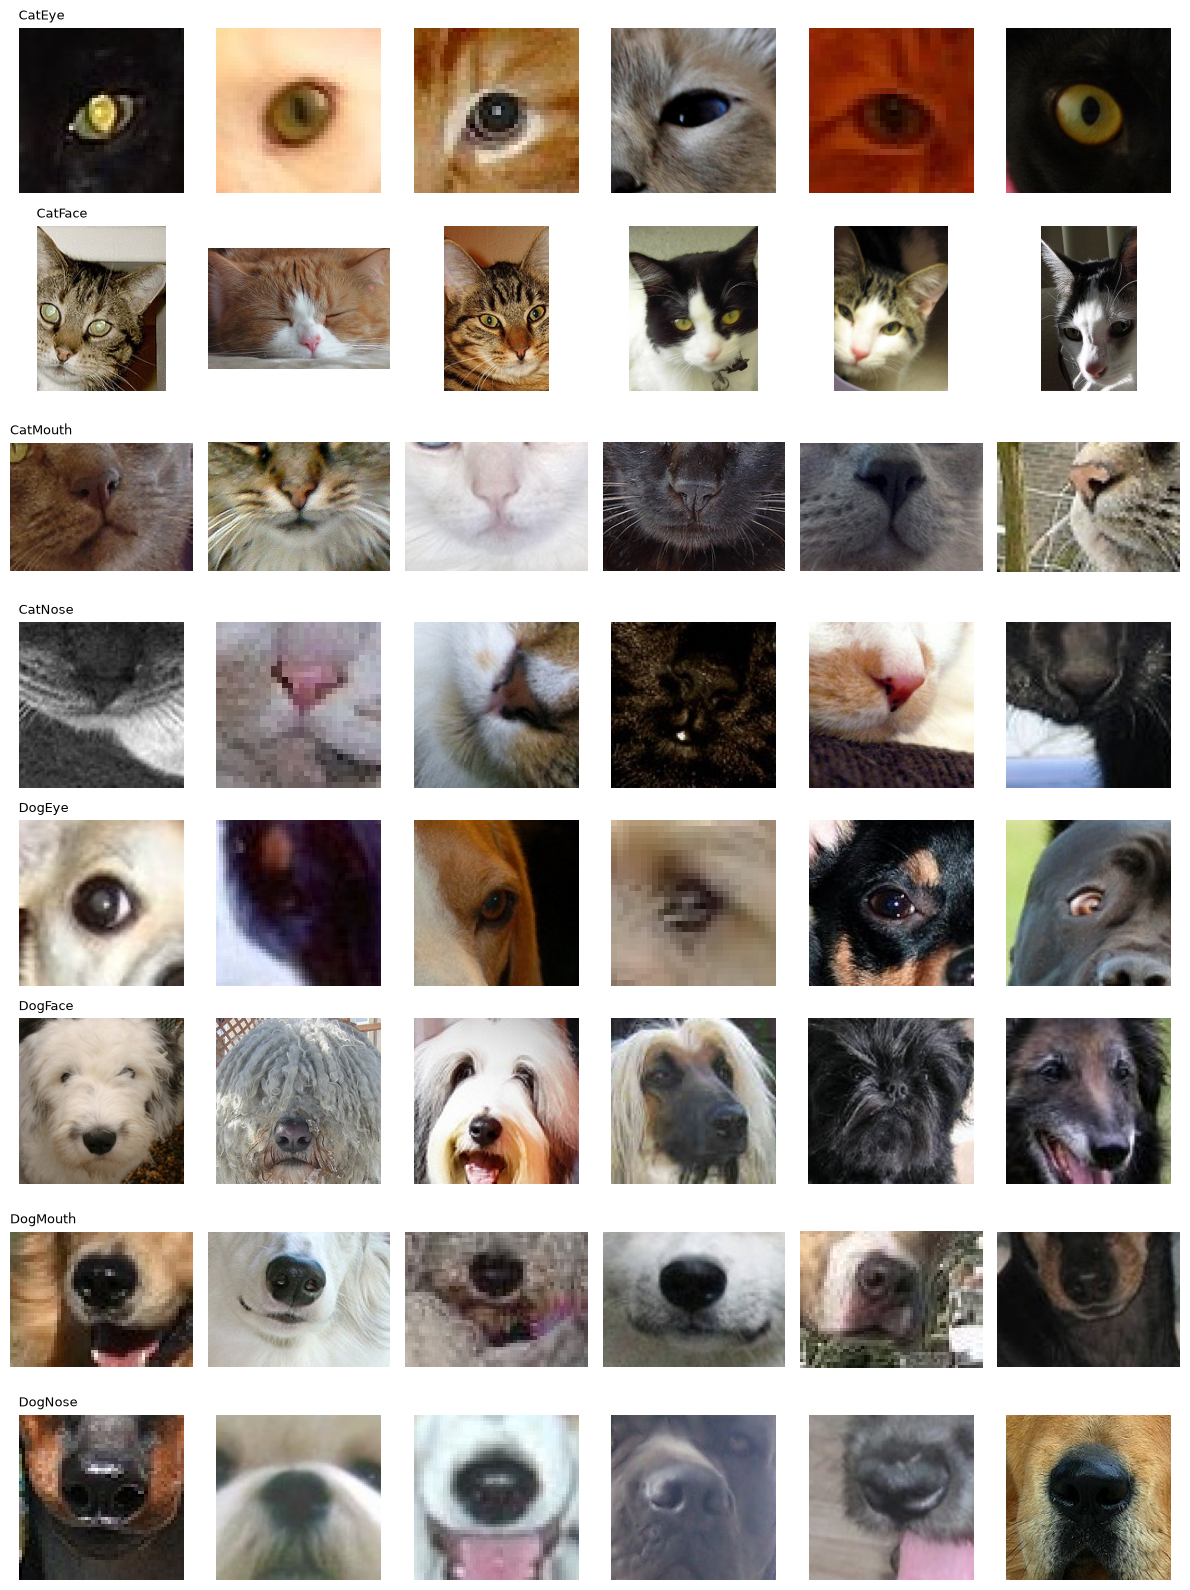

In [4]:
classes = list(counts.index)
n = 6
fig, axes = plt.subplots(len(classes), n, figsize=(2 * n, 2 * len(classes)))
for r, cls in enumerate(classes):
    paths = df[df["class"] == cls]["path"].sample(n, random_state=SEED)
    for c, p in enumerate(paths):
        axes[r, c].imshow(Image.open(p).convert("RGB")); axes[r, c].axis("off")
        if c == 0:
            axes[r, c].set_title(cls, fontsize=9, loc="left")
plt.tight_layout(); plt.show()

corrupt files: 0
            w       h     blur
count  3000.0  3000.0   3000.0
mean    114.0   109.6   2461.8
std      90.5    93.7   3142.2
min      10.0    10.0      8.1
25%      54.0    50.0    563.6
50%      85.5    80.0   1355.5
75%     144.0   132.0   3159.2
max     829.0   958.0  36210.3
colour modes: {'RGB': 3000}
images with a side under 16 px: 11


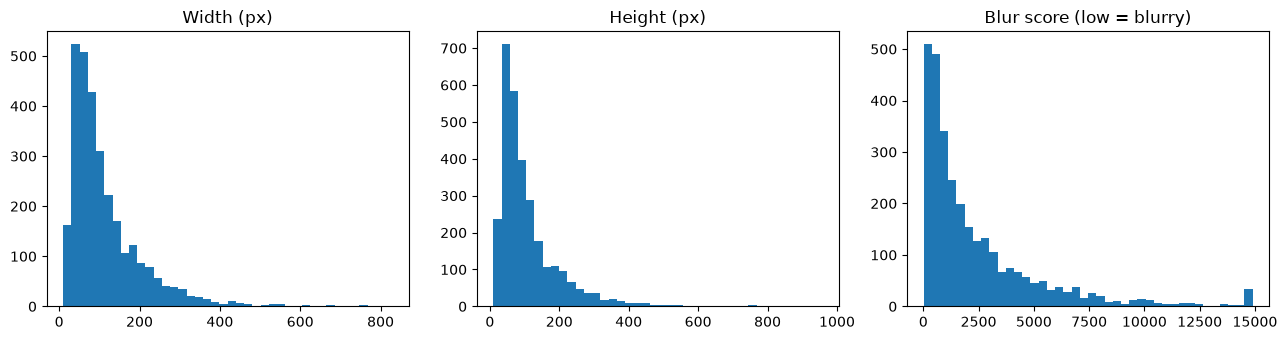

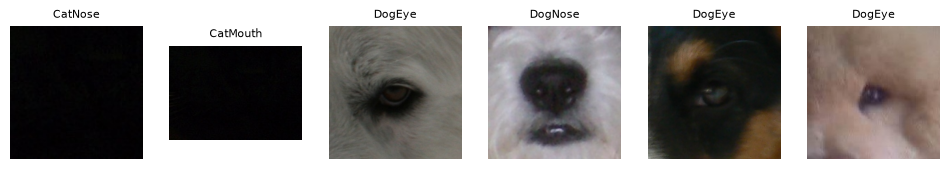

In [5]:
subset = df.sample(3000, random_state=SEED)
rows, corrupt = [], []
for p in subset["path"]:
    try:
        with Image.open(p) as im:
            im.verify()                                   # raises an error for truncated/corrupt files
        with Image.open(p) as im:
            g = np.asarray(im.convert("L"), dtype=np.float32)
            # Laplacian = how much each pixel differs from its 4 neighbours; low variance = blurry
            lap = -4*g[1:-1,1:-1] + g[:-2,1:-1] + g[2:,1:-1] + g[1:-1,:-2] + g[1:-1,2:]
            rows.append((p, im.size[0], im.size[1], im.mode, float(lap.var())))
    except Exception as e:
        corrupt.append((str(p), repr(e)))

q = pd.DataFrame(rows, columns=["path", "w", "h", "mode", "blur"])
print("corrupt files:", len(corrupt))
print(q[["w", "h", "blur"]].describe().round(1).to_string())
print("colour modes:", q["mode"].value_counts().to_dict())
print("images with a side under 16 px:", int(((q["w"] < 16) | (q["h"] < 16)).sum()))

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
ax[0].hist(q["w"], bins=40); ax[0].set_title("Width (px)")
ax[1].hist(q["h"], bins=40); ax[1].set_title("Height (px)")
ax[2].hist(q["blur"].clip(upper=q["blur"].quantile(0.99)), bins=40); ax[2].set_title("Blur score (low = blurry)")
plt.tight_layout(); plt.show()

worst = q.nsmallest(6, "blur")["path"].tolist()           # the blurriest images
fig, axes = plt.subplots(1, 6, figsize=(12, 2.4))
for a, p in zip(axes, worst):
    a.imshow(Image.open(p).convert("RGB")); a.axis("off")
    a.set_title(df.loc[df["path"] == p, "class"].iloc[0], fontsize=8)
plt.show()

In [6]:
def md5(p):
    return hashlib.md5(Path(p).read_bytes()).hexdigest()   # fingerprint of the file's bytes

with ThreadPoolExecutor(max_workers=os.cpu_count()) as ex:
    df["md5"] = list(ex.map(md5, df["path"]))
dups = df[df.duplicated("md5", keep=False)]
print(f"duplicate files in train: {len(dups)} ({dups['md5'].nunique()} groups)")
print("duplicate groups with conflicting labels:", int((dups.groupby('md5')['class'].nunique() > 1).sum()))

with ThreadPoolExecutor(max_workers=os.cpu_count()) as ex:
    test_hashes = set(ex.map(md5, TEST_PATHS))
print("train images identical to a test image:", int(df["md5"].isin(test_hashes).sum()))

duplicate files in train: 30 (15 groups)
duplicate groups with conflicting labels: 0
train images identical to a test image: 0
